# Retail customer & revenue analytics: walkthrough

This notebook goes through the analysis step by step. The actual code is in the
`retail_analytics` package and the SQL files in `sql/`. The notebook calls them and
explains what the results mean.

Data: UCI Online Retail II, 1,067,371 transaction lines from a UK online giftware
retailer, Dec 2009 to Dec 2011. Run `make data && make all` before executing this notebook.

In [1]:
import json
import pandas as pd
from IPython.display import Image, Markdown, display

from retail_analytics import basket, clv, cohorts, forecasting, paths, revenue, segmentation, warehouse

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_colwidth", 60)
metrics = json.loads(paths.METRICS_JSON.read_text())
FIG = paths.FIGURES_DIR

## 1. Data quality

Rows that are actually wrong get removed. Everything else is kept and tagged with a
`line_type` (sale, cancellation, postage, ...).

In [2]:
audit = pd.read_csv(paths.TABLES_DIR / "data_quality_audit.csv")
audit[["step", "rule", "rows", "revenue_gbp", "action"]]

,step,rule,rows,revenue_gbp,action
0,Raw input,Both sheets of online_retail_II.xlsx stacked,1067371,"19,287,250.568",loaded
1,Remove sheet overlap,Rows dated >= 2010-12-01 in the 2009-2010 sheet (duplica...,22523,"377,488.450",removed
2,Drop unparseable,Missing date / quantity / price / stock code,0,0.000,removed
3,Drop exact duplicates,Fully identical line items within an invoice,11812,"54,228.420",removed
4,Classify,line_type = sale,1003340,"19,643,861.620",flagged
5,Classify,line_type = cancellation,17914,"-716,425.970",flagged
6,Classify,line_type = non_product,5813,"75,712.128",flagged
7,Classify,line_type = stock_adjustment,3392,0.000,flagged
8,Classify,line_type = bad_debt_adjustment,6,"-147,614.080",flagged
9,Classify,line_type = zero_price,2571,0.000,flagged


The biggest one: both Excel sheets contain 1-9 Dec 2010, so stacking them double counts
22,523 rows and about £377k of revenue, and every KPI after that would be off.

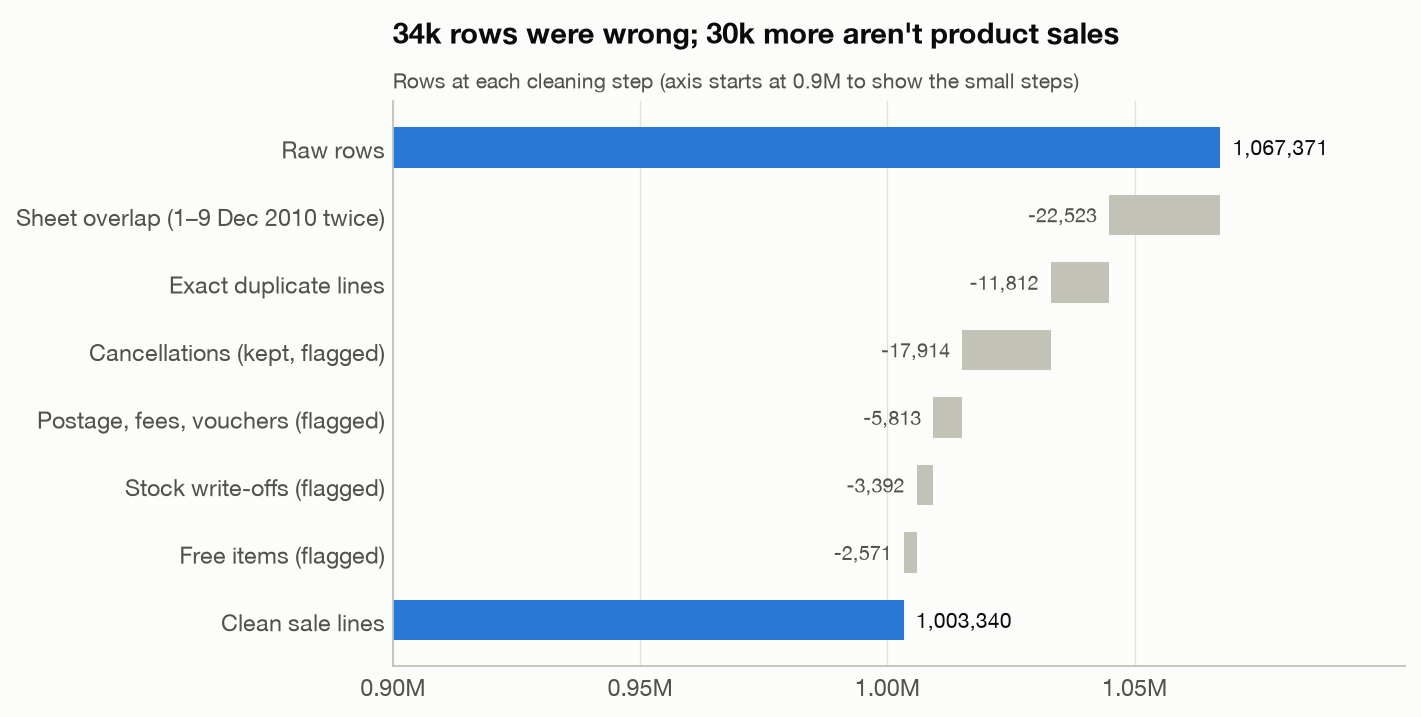

In [3]:
display(Image(FIG / "01_data_quality.png", width=760))

## 2. SQL warehouse

The clean parquet file is loaded into DuckDB as a small star schema (`fct_order_lines`,
`fct_orders`, `dim_date`, `dim_product`, `dim_customer`) with KPI views on top. The monthly
KPI view:

In [4]:
print((paths.SQL_DIR / "10_kpi_monthly.sql").read_text()[:1400])

-- 10_kpi_monthly.sql
-- Monthly business KPIs. Definitions live in docs/metric_definitions.md.
--   gross_sales      merchandise sales before cancellations
--   net_revenue      gross_sales + cancellations (cancellations are negative)
--   aov              gross_sales / orders
--   new vs returning split uses the customer's first order month in the data window
--   (Dec-2009 "new" customers are left-censored: many were existing customers).
CREATE OR REPLACE VIEW kpi_monthly AS
WITH money AS (
    SELECT
        DATE_TRUNC('month', date_key)::DATE                          AS month,
        SUM(revenue) FILTER (WHERE line_type = 'sale')               AS gross_sales,
        SUM(revenue) FILTER (WHERE line_type = 'cancellation')       AS cancellations,
        SUM(revenue)                                                 AS net_revenue,
        SUM(quantity) FILTER (WHERE line_type = 'sale')              AS units
    FROM fct_order_lines
    GROUP BY 1
),
orders AS (
    SELECT
        DA

In [5]:
warehouse.query("""
    SELECT month, ROUND(net_revenue) AS net_revenue, orders, active_customers,
           ROUND(aov, 1) AS aov, ROUND(cancellation_rate, 3) AS cancel_rate
    FROM kpi_monthly
    WHERE month BETWEEN '2011-01-01' AND '2011-11-01'
""")

,month,net_revenue,orders,active_customers,aov,cancel_rate
0,2011-01-01,"578,855.000",1081,739,620.100,0.137
1,2011-02-01,"499,464.000",1093,757,464.600,0.016
2,2011-03-01,"679,329.000",1440,973,479.100,0.015
3,2011-04-01,"482,062.000",1235,853,417.300,0.065
4,2011-05-01,"731,005.000",1668,1054,443.600,0.012
5,2011-06-01,"723,845.000",1525,990,483.600,0.019
6,2011-07-01,"676,812.000",1452,946,474.000,0.017
7,2011-08-01,"701,290.000",1339,933,540.900,0.032
8,2011-09-01,"1,011,340.000",1818,1259,565.600,0.017
9,2011-10-01,"1,061,701.000",2005,1361,550.300,0.038


Days between orders (uses LAG), which is useful later for deciding when a customer counts as at risk:

In [6]:
warehouse.query("""
    SELECT quantile_cont(days_since_prev_order, 0.50) AS p50,
           quantile_cont(days_since_prev_order, 0.75) AS p75,
           quantile_cont(days_since_prev_order, 0.90) AS p90
    FROM purchase_intervals
""")

,p50,p75,p90
0,32.000,70.000,148.000


## 3. Revenue

In [7]:
ty = revenue.trading_year_summary()
ty[["net_revenue", "orders", "active_customers", "orders_per_customer", "aov", "cancellation_rate"]].T

trading_year,2010,2011
net_revenue,"9,156,117.490","9,330,918.600"
orders,"19,743.000","18,957.000"
active_customers,"4,239.000","4,293.000"
orders_per_customer,4.292,4.106
aov,475.948,508.136
cancellation_rate,0.026,0.031


In [8]:
bridge = revenue.revenue_bridge(ty)
display(bridge)
print(f"Contributions sum to £{bridge.contribution_gbp.sum():,.0f}; "
      f"actual change £{ty.loc[2011, 'gross_sales'] - ty.loc[2010, 'gross_sales']:,.0f}")

,contribution_gbp,pct_of_base
Active customers,"104,787.012",0.011
Orders per customer,"-366,430.542",-0.039
Average order value,"155,288.009",0.017
Guest (no-ID) sales,"342,441.620",0.036


Contributions sum to £236,086; actual change £236,086


The parts add up exactly to the total change. Growth came from bigger orders, slightly more
customers and guest orders, while each customer ordered less often (-£366k).

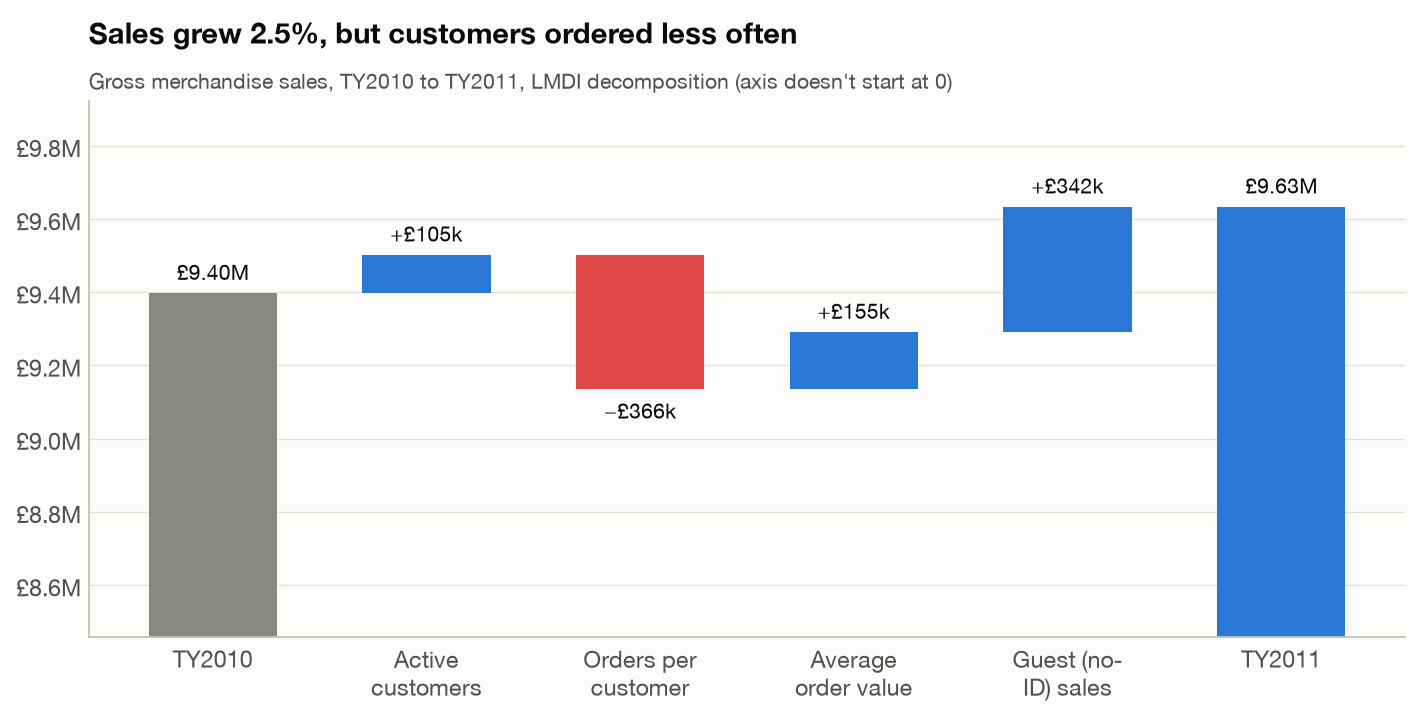

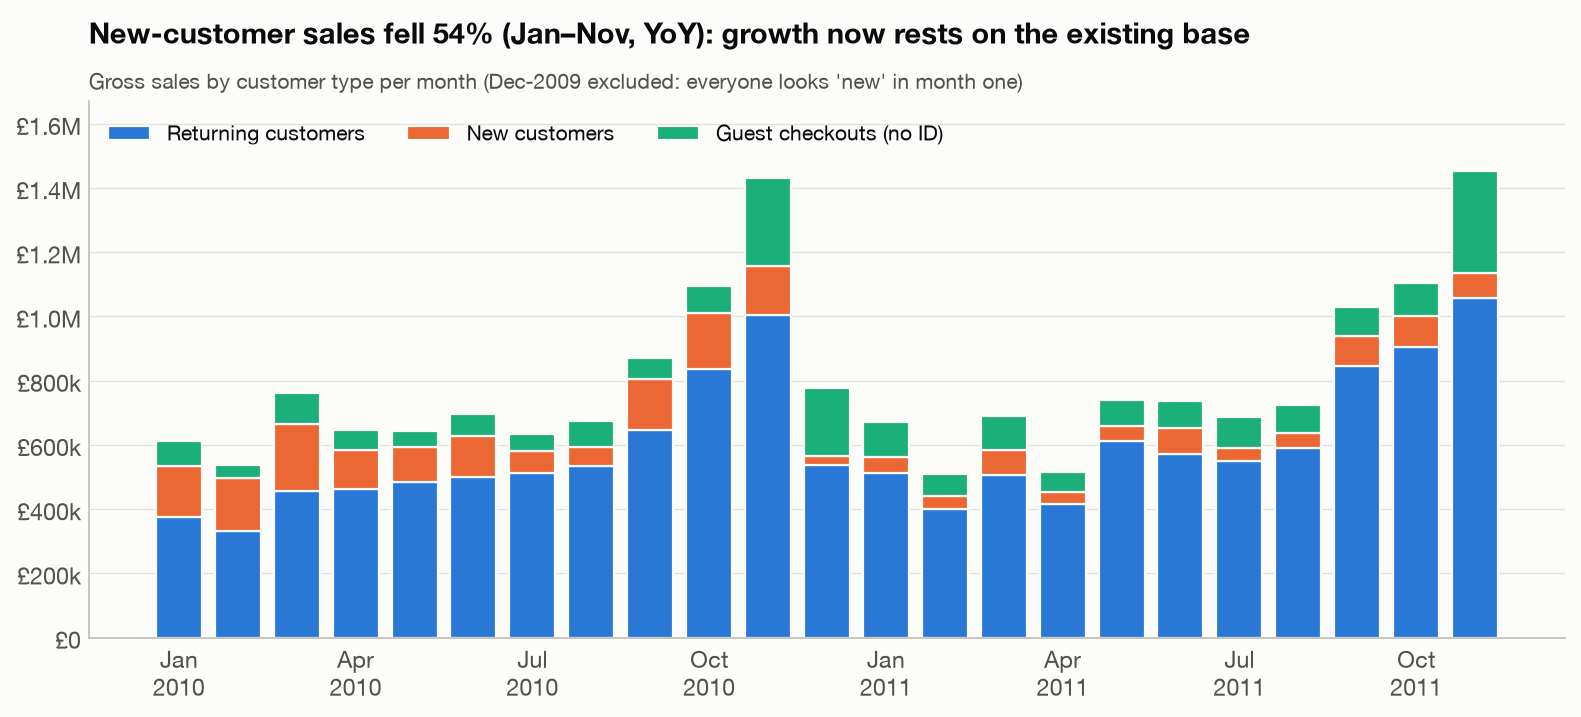

In [9]:
display(Image(FIG / "03_revenue_bridge.png", width=760)); display(Image(FIG / "04_new_vs_returning.png", width=760))

## 4. Cohorts

The Dec 2009 cohort is left out of the comparison. The data starts that month, so it includes
every existing customer, not just new ones.

In [10]:
mat = cohorts.retention_matrix()
display(cohorts.compare_cohort_vintages(mat))
print(f"Established base (Dec-2009) still ordering 12 months later: {cohorts.established_base_retention(mat):.0%}")

,M1,M3,M6
2010 cohorts (Jan-Jun),0.194,0.232,0.220
2011 cohorts (Jan-Jun),0.203,0.201,0.174


Established base (Dec-2009) still ordering 12 months later: 38%


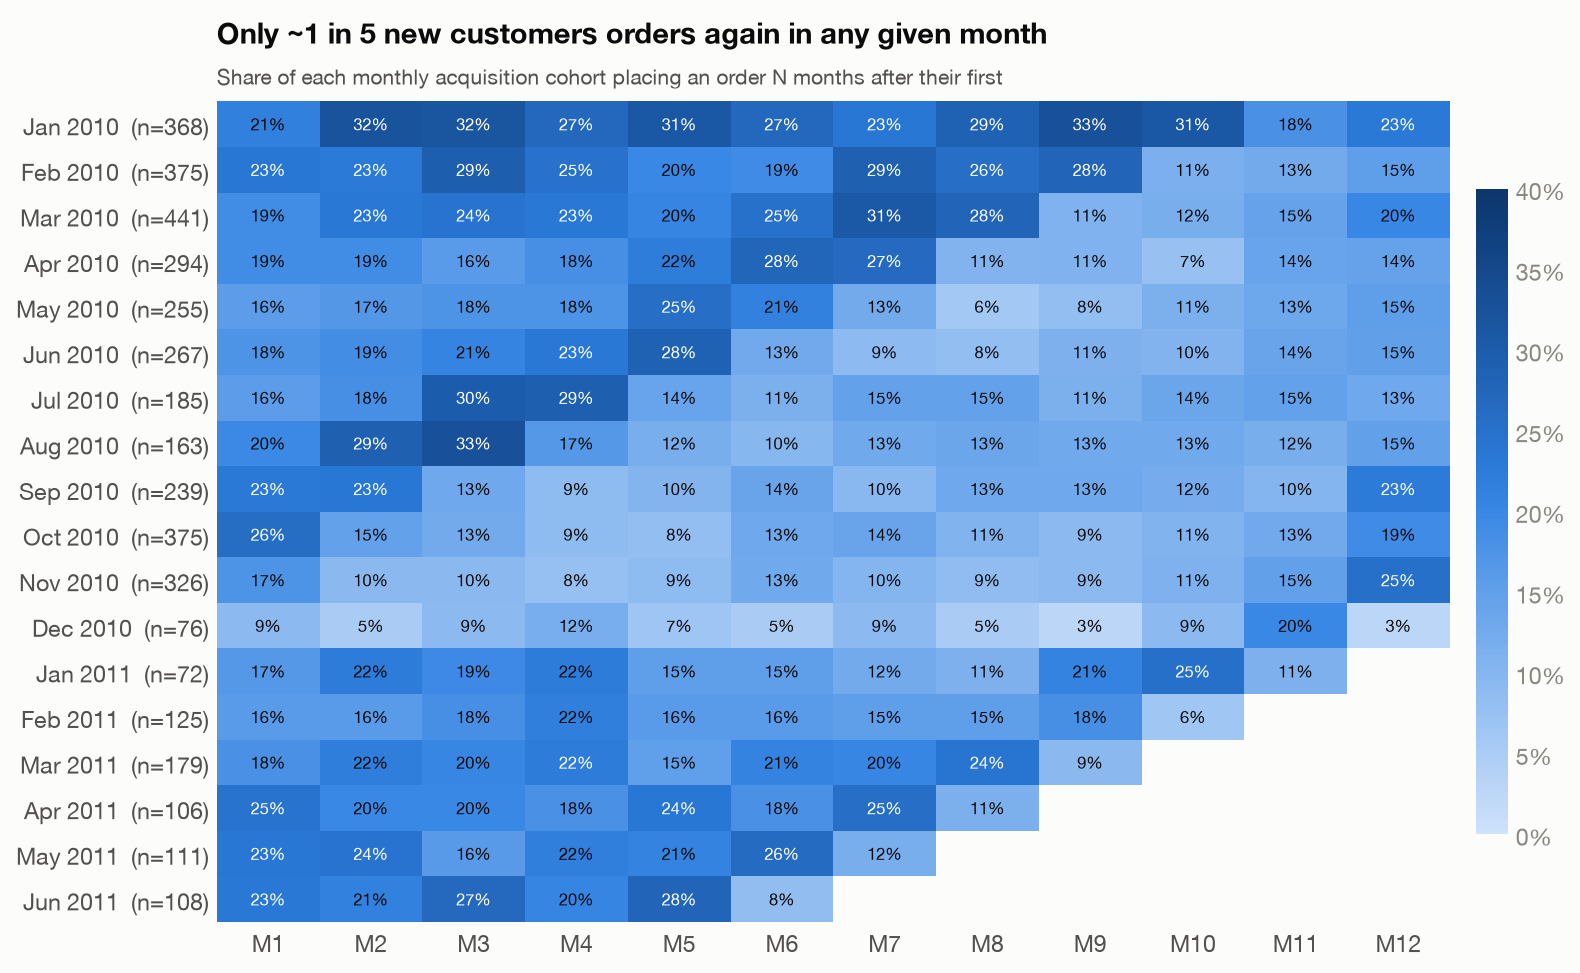

In [11]:
display(Image(FIG / "05_cohort_retention.png", width=760))

## 5. RFM segments (and a k-means check)

In [12]:
rfm = segmentation.rfm_table()
seg = segmentation.segment_summary(rfm)
seg[["customers", "customer_share", "revenue_share", "median_recency_days", "avg_orders", "action"]]

,customers,customer_share,revenue_share,median_recency_days,avg_orders,action
segment,,,,,,
Champions,1556,0.267,0.716,18.000,14.841,"Reward & protect: early access, referral asks, no discou..."
Loyal,574,0.098,0.113,93.000,7.899,Upsell premium ranges; loyalty tier; ask for reviews.
Potential Loyalists,686,0.118,0.025,25.000,2.335,"Nudge the 2nd/3rd order: bundles from basket analysis, f..."
New & Promising,93,0.016,0.001,27.000,1.000,Onboarding series; best-seller recommendations; second-o...
Needs Attention,496,0.085,0.019,96.000,2.260,Time-limited offer on categories they already buy.
Can't Lose Them,110,0.019,0.042,314.000,12.755,Personal outreach from account managers (most revenue at...
At Risk,856,0.147,0.060,380.000,3.473,Win-back campaign before they lapse (90+ days since last...
About to Sleep,97,0.017,0.001,107.000,1.000,"Low-cost reactivation (newsletter, seasonal catalogue)."
Hibernating / Lost,1369,0.235,0.023,436.000,1.214,Suppress from paid channels; occasional low-cost win-bac...


In [13]:
km = segmentation.kmeans_check(rfm)
print("silhouette by k:", {k: round(v, 3) for k, v in km["silhouette"].items()}, "→ best k =", km["best_k"])
km["profile"]

silhouette by k: {3: 0.349, 4: 0.362, 5: 0.34, 6: 0.332, 7: 0.312, 8: 0.297} → best k = 4


,customers,median_recency,median_orders,median_revenue
cluster,,,,
1,1194,17.000,13.000,"4,797.755"
3,1436,185.000,4.000,"1,418.900"
2,1258,24.000,3.000,706.545
0,1949,402.000,1.000,264.500


## 6. Customer lifetime value (BG/NBD + Gamma-Gamma)

Fit on Dec 2009 to Jun 2011, predict the next 26 weeks and compare with what actually happened.

In [14]:
tx = clv.load_transactions()
val = clv.holdout_validation(tx)
m = val["metrics"]
pd.Series({
    "actual purchases": m["actual_total_purchases"],
    "BG/NBD predicted": round(m["bgnbd_total_purchases"]),
    "naive predicted": round(m["naive_total_purchases"]),
    "MAE BG/NBD": round(m["bgnbd_mae"], 2),
    "MAE naive": round(m["naive_mae"], 2),
    "rank corr BG/NBD": round(m["bgnbd_spearman"], 3),
})

actual purchases    7,721.000
BG/NBD predicted    7,605.000
naive predicted    13,137.000
MAE BG/NBD              1.040
MAE naive               1.700
rank corr BG/NBD        0.624
dtype: float64

Same test with less history. With only 12 months, customers who first bought in Q4 look like
heavy buyers and the forecast is far too high:

In [15]:
clv.calibration_sensitivity(tx)

,calibration,holdout_weeks,predicted / actual purchases,MAE (BG/NBD),MAE (naive),rank corr (BG/NBD)
0,Dec-2009 to Dec-2010,52.100,1.539,2.505,5.777,0.574
1,Dec-2009 to Mar-2011,39.300,1.131,1.530,2.933,0.607
2,Dec-2009 to Jun-2011,26.100,0.985,1.043,1.696,0.624


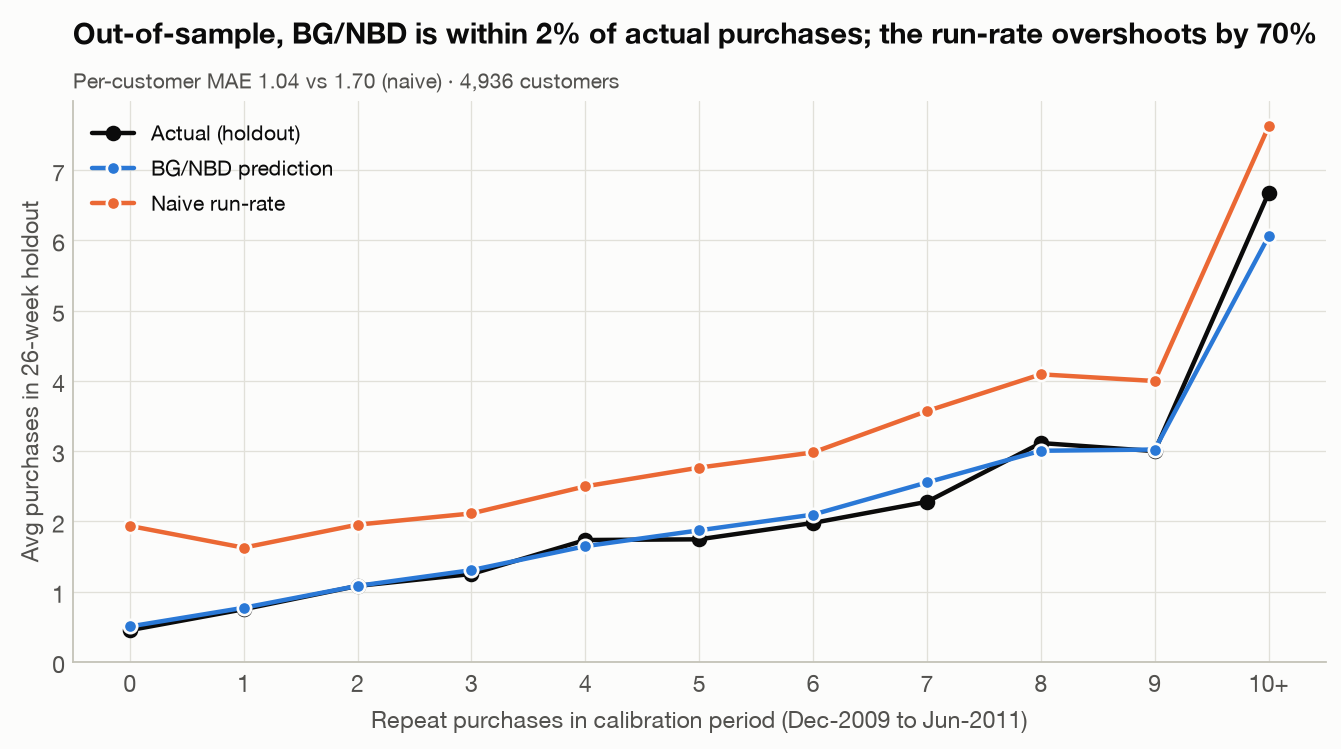

In [16]:
display(Image(FIG / "08_clv_validation.png", width=760))

## 7. Basket analysis

In [17]:
rules = basket.dedupe_symmetric(basket.add_descriptions(basket.pair_rules(basket.load_baskets(), min_support=0.01)))
print(f"{len(rules)} rules; share of top-50 that are sibling designs: {basket.same_collection_share(rules.head(50)):.0%}")
rules.head(10)[["antecedent_name", "consequent_name", "support", "confidence", "lift"]]

534 rules; share of top-50 that are sibling designs: 88%


,antecedent_name,consequent_name,support,confidence,lift
0,COFFEE MUG DOG + BALL DESIGN,COFFEE MUG CAT + BIRD DESIGN,0.010,0.750,45.926
1,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE BEDROOM,0.012,0.817,45.684
2,POPPY'S PLAYHOUSE LIVINGROOM,POPPY'S PLAYHOUSE KITCHEN,0.012,0.842,44.537
3,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.014,0.793,41.973
4,SMALL MARSHMALLOWS PINK BOWL,SMALL DOLLY MIX DESIGN ORANGE BOWL,0.012,0.762,41.236
5,WOODEN TREE CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.011,0.790,40.421
6,SET/10 BLUE SPOTTY PARTY CANDLES,SET/10 PINK POLKADOT PARTY CANDLES,0.012,0.775,37.841
7,"KEY FOB , GARAGE DESIGN","KEY FOB , BACK DOOR",0.010,0.646,36.872
8,FELTCRAFT PRINCESS LOLA DOLL,FELTCRAFT PRINCESS CHARLOTTE DOLL,0.010,0.621,35.569
9,PINK POLKADOT CUP,BLUE POLKADOT CUP,0.013,0.693,35.527


## 8. Forecasting

In [18]:
series = forecasting.weekly_series()
scores = forecasting.score(forecasting.backtest(series))
scores

,WAPE (1-4 wk),WAPE (1 wk),Bias
model,,,
ensemble,0.137,0.143,-0.056
harmonic,0.154,0.155,-0.051
seasonal_naive,0.156,0.169,-0.062
drift_naive,0.188,0.168,-0.117
ets,0.188,0.184,-0.085


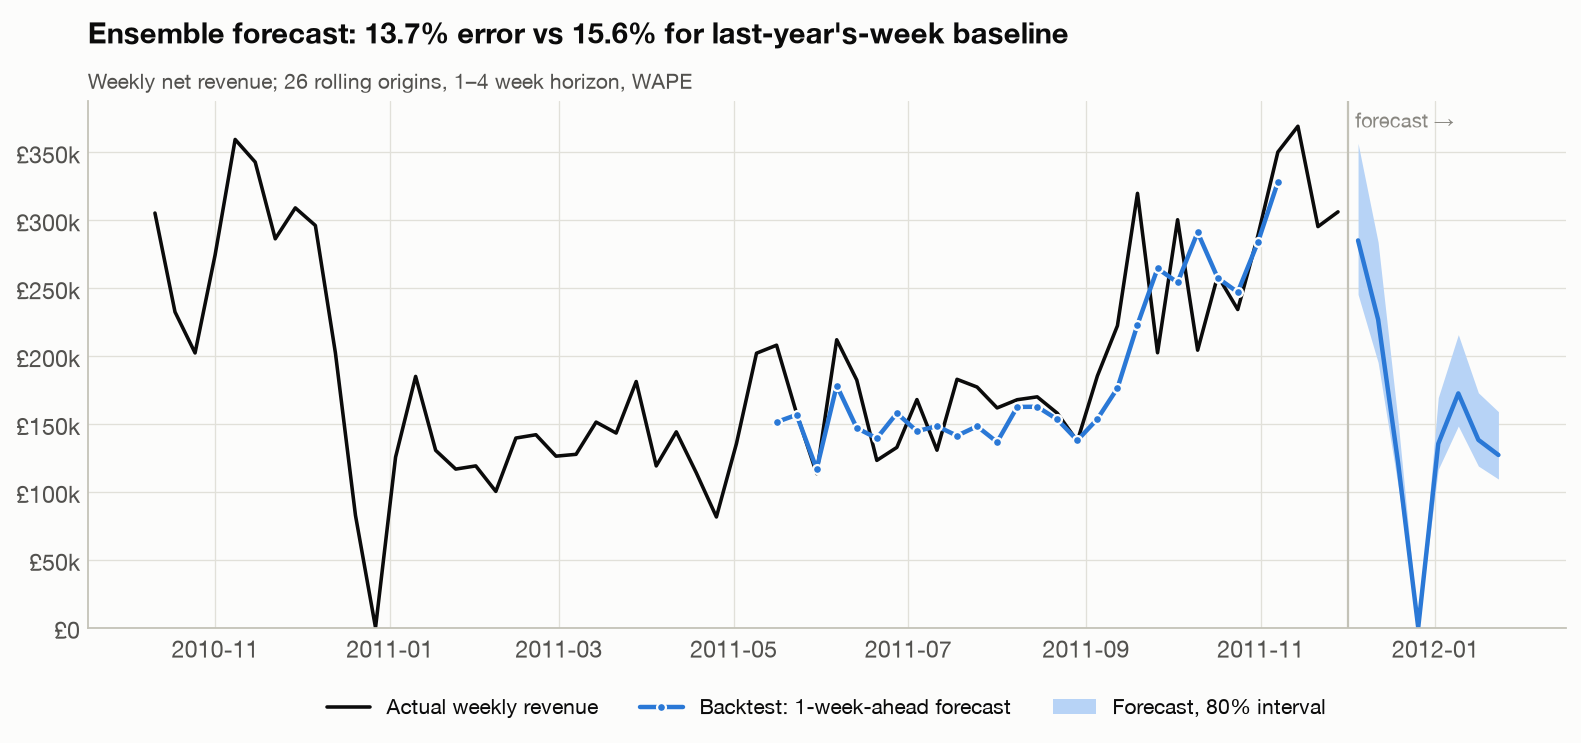

In [19]:
display(Image(FIG / "13_forecast.png", width=760))

## 9. Recommendations

1. Track new-customer acquisition as a KPI (first-time sales fell 54%).
2. Second-order campaign (reminder at day 30, offer at day 60), tested as an A/B test.
3. Account managers contact the 110 "Can't Lose Them" customers.
4. "Complete the set" recommendations and bundles.
5. Plan Q4 stock and staffing from the weekly forecast.
6. Look into Spanish cancellations and capture IDs on guest orders.

More detail in `reports/executive_summary.md`.